<a href="https://colab.research.google.com/github/VadymChubLabs/IAD/blob/main/Lab3_Neural_Networks.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота №3. Нейронні мережі в PyTorch

**Мета.** Побудувати MLP для табличних даних, CNN для зображень і GRU для SMS. Дослідити перенавчання, вплив обсягу даних і попередньо навчених ваг.


## Підготовка

`TensorDataset` зберігає ознаки й мітки, `Subset` вибирає потрібні рядки, а `DataLoader` збирає їх у батчі. Для train порядок зразків перемішується. Фіксований seed задає порядок перемішування й початкові ваги. Файли даних завантажуються один раз і зберігаються в кеші.

In [1]:
from collections import Counter
from copy import deepcopy
import gzip
import html
import os
from pathlib import Path
import re
from shutil import copyfileobj
import tarfile
from tempfile import TemporaryDirectory
from time import perf_counter
from urllib.request import urlopen
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
from sklearn.metrics import accuracy_score, f1_score, precision_recall_fscore_support
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from torch import nn
from torch.utils.data import DataLoader, Subset, TensorDataset
from torchvision import datasets, transforms
from torchvision.models import MobileNet_V3_Small_Weights, mobilenet_v3_small

SEED = 42
DEVICE = "cpu"
CACHE = Path(os.environ.get("IAD_LAB3_CACHE", Path.home() / ".cache" / "iad-lab3"))
CACHE.mkdir(parents=True, exist_ok=True)


def download(filename, url):
    path = CACHE / filename
    if not path.exists():
        temporary = path.with_suffix(path.suffix + ".part")
        with urlopen(url, timeout=90) as response, temporary.open("wb") as output:
            copyfileobj(response, output)
        temporary.replace(path)
    return path


def loader(dataset, batch_size, shuffle=False):
    return DataLoader(
        dataset, batch_size=batch_size, shuffle=shuffle,
        generator=torch.Generator().manual_seed(SEED),
    )

### Навчання й оцінювання

**Прямий прохід.** `model(inputs)` пропускає батч через шари й повертає логіти $z$, тобто оцінки класів. Softmax перетворює їх на ймовірності. Для справжнього класу $y$ перехресна ентропія дорівнює $-\log(\operatorname{softmax}(z)_y)$. Вона зростає, коли модель дає правильному класу малу ймовірність. `CrossEntropyLoss` виконує це обчислення з логітів.

**Зворотний прохід.** `zero_grad()` очищає градієнти попереднього батча. `backward()` за правилом ланцюга обчислює, як зміна кожної ваги вплине на середню втрату. `optimizer.step()` оновлює ваги за цими градієнтами. AdamW масштабує крок за згладженими середніми градієнтів і їхніх квадратів та окремо застосовує decay до ваг. `lr` задає загальний масштаб кроку.

Епоха - один повний прохід по train. Після кожної епохи `run_epoch` вимірює втрату на validation у режимі оцінювання, із вимкненими dropout та обчисленням градієнтів. `fit` відновлює ваги епохи з найменшим validation loss. На тесті `predict` вибирає індекс найбільшого логіта як клас.


In [2]:
def run_epoch(model, batches, loss_fn, optimizer=None, frozen=None):
    training = optimizer is not None
    model.train(training)
    if frozen is not None:
        frozen.eval()

    total_loss = torch.zeros((), device=DEVICE)
    with torch.set_grad_enabled(training):
        for inputs, labels in batches:
            inputs, labels = inputs.to(DEVICE), labels.to(DEVICE)
            if training:
                optimizer.zero_grad(set_to_none=True)
            losses = loss_fn(model(inputs), labels)
            if training:
                losses.mean().backward()
                optimizer.step()
            total_loss += losses.detach().sum()
    return total_loss.item() / len(batches.dataset)


def fit(model, train_batches, val_batches, optimizer, epochs, loss_fn, frozen=None):
    history = []
    best_loss = float("inf")
    start = perf_counter()
    for epoch in range(1, epochs + 1):
        train_loss = run_epoch(model, train_batches, loss_fn, optimizer, frozen)
        val_loss = run_epoch(model, val_batches, loss_fn)
        if val_loss < best_loss:
            best_loss = val_loss
            best_weights = deepcopy(model.state_dict())
        history.append({
            "epoch": epoch, "train_loss": train_loss, "val_loss": val_loss,
            "seconds": perf_counter() - start,
        })
    model.load_state_dict(best_weights)
    return pd.DataFrame(history).set_index("epoch")


@torch.no_grad()
def predict(model, batches):
    model.eval()
    actual, predicted = [], []
    for inputs, labels in batches:
        actual.append(labels)
        predicted.append(model(inputs.to(DEVICE)).argmax(dim=1).cpu())
    return torch.cat(actual).numpy(), torch.cat(predicted).numpy()


cross_entropy = nn.CrossEntropyLoss(reduction="none")

### Криві та метрики

`learning_curves` показує середній loss за епохами. Якщо train і validation loss падають, покращення поширюється на дані, яких модель не бачила під час оновлення ваг. Якщо train loss далі падає, а validation loss стійко зростає, модель підлаштовується під train і гірше узагальнює. Це ознака перенавчання. Пунктир позначає епоху, ваги якої використаємо на test.

Accuracy - частка правильних прогнозів. Macro F1 - середнє F1 за всіма класами з однаковою вагою для кожного класу. Час у таблицях включає проходи train і validation після підготовки даних та ініціалізації моделі.

Конспект `DataAnalysisNotes`, с. 5 і 26.

In [15]:
def learning_curves(histories):
    columns = min(2, len(histories))
    rows = (len(histories) + columns - 1) // columns
    fig, axes = plt.subplots(rows, columns, figsize=(5.1 * columns, 3.3 * rows),
                             squeeze=False, sharey=True, layout="constrained")
    for ax, (title, history) in zip(axes.flat, histories.items()):
        best_epoch = history["val_loss"].idxmin()
        ax.plot(history.index, history["train_loss"], label="Train")
        ax.plot(history.index, history["val_loss"], label="Validation")
        ax.axvline(best_epoch, color="gray", linestyle=":", label="Мінімум validation")
        ax.set(title=title, xlabel="Епоха", ylabel="Cross-entropy")
        ax.grid(alpha=0.2)
        ax.legend()
    plt.show()


def convergence(history):
    best_epoch = history["val_loss"].idxmin()
    return {
        "Val loss (1-ша)": history["val_loss"].iloc[0],
        "Найкраща епоха": best_epoch,
        "Мін. val loss": history.loc[best_epoch, "val_loss"],
        "Секунд до мін.": history.loc[best_epoch, "seconds"],
        "Секунд загалом": history["seconds"].iloc[-1],
    }

## 1. MLP для Raisin

У наборі 900 зразків, сім числових ознак форми та два сорти родзинок, Besni і Kecimen. Відтворюємо стратифікований 80/20 поділ Lab 1 із seed 42. З 720 навчальних зразків виділяємо 144 для валідації. Стандартизацію навчаємо на решті 576, щоб середні та масштаби ознак визначалися тільки за даними train.

[Набір даних UCI Raisin](https://archive.ics.uci.edu/dataset/850/raisin)

In [4]:
raisin_file = download("raisin.csv", "https://archive.ics.uci.edu/static/public/850/data.csv")
raisin = pd.read_csv(raisin_file)
X = raisin.drop(columns="Class")
y = raisin["Class"].map({"Besni": 0, "Kecimen": 1}).to_numpy()

raisin_dev, raisin_test = train_test_split(
    np.arange(len(y)), test_size=0.2, stratify=y, random_state=SEED,
)
raisin_train, raisin_val = train_test_split(
    raisin_dev, test_size=0.2, stratify=y[raisin_dev], random_state=SEED,
)
scaler = StandardScaler().fit(X.iloc[raisin_train])
raisin_split = TensorDataset(torch.tensor(scaler.transform(X), dtype=torch.float32),
                             torch.tensor(y, dtype=torch.long))
tab_train = loader(Subset(raisin_split, raisin_train), 32, shuffle=True)
tab_val = loader(Subset(raisin_split, raisin_val), 32)
tab_test = loader(Subset(raisin_split, raisin_test), 32)
print(f"Train / validation / test: {len(raisin_train)} / {len(raisin_val)} / {len(raisin_test)}")

Train / validation / test: 576 / 144 / 180


### Модель і порівняння з Lab 1

У повнозв’язному шарі кожен вихід використовує всі значення попереднього шару. `Linear` обчислює $Wx+b$, де $W$ - ваги, а $b$ - зсув. `ReLU` застосовує $\max(0,x)$ до кожного числа. Саме ця нелінійність дає змогу MLP навчити нелінійну межу між сортами. Послідовність шарів у роботі має розміри $7 \to 32 \to 16 \to 2$. Два виходи є логітами Besni і Kecimen.

Під графіком порівнюємо accuracy MLP із результатами Lab 1 для того самого тесту. У MLP ваги оновлюються через градієнти, а kNN визначає клас за голосами найближчих зразків у просторі ознак.


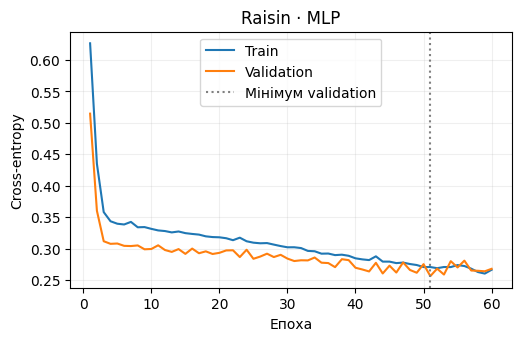

,Test accuracy
MLP,0.8889
kNN,0.8833
AdaBoost,0.8778
SVM,0.8722
Random Forest,0.8667
Decision Tree,0.8444


In [5]:
torch.manual_seed(SEED)
mlp = nn.Sequential(
    nn.Linear(X.shape[1], 32), nn.ReLU(),
    nn.Linear(32, 16), nn.ReLU(),
    nn.Linear(16, 2),
).to(DEVICE)
mlp_history = fit(mlp, tab_train, tab_val, torch.optim.AdamW(mlp.parameters(), lr=0.003),
                  epochs=60, loss_fn=cross_entropy)
actual, predicted = predict(mlp, tab_test)
learning_curves({"Raisin · MLP": mlp_history})

# Кількість правильних відповідей із таблиці результатів Lab 1 (180 тестових зразків).
raisin_results = pd.Series({
    "MLP": accuracy_score(actual, predicted),
    "kNN": 159 / 180, "AdaBoost": 158 / 180, "SVM": 157 / 180,
    "Random Forest": 156 / 180, "Decision Tree": 152 / 180,
}, name="Test accuracy").sort_values(ascending=False)
display(raisin_results.to_frame().round(4))

**Висновок.** У перші епохи train і validation loss швидко знижуються, далі зміни поступові. Мінімум validation loss становить 0,256 на 51-й епосі. Після нього крива коливається близько 0,27 без стійкого зростання, тож ознак вираженого перенавчання немає.

MLP дала 88,89% accuracy (160 із 180), а найкраща класична модель kNN - 88,33% (159 із 180). Різниця становить один зразок. Класичні моделі навчалися на 720 прикладах, а MLP - на 576 із виділеною validation вибіркою. За одним розбиттям ці результати близькі.

## 2. CNN для класифікації квітів

TensorFlow Flowers містить 3 670 кольорових фотографій у п’яти класах. `ImageFolder` присвоює клас за назвою папки. Під час підготовки до навчання перетворюємо кадри на тензори 128×128 і нормалізуємо RGB-канали за статистиками ImageNet. Клітинка показує кількість фотографій і по одному прикладу з кожного класу.

[TensorFlow Flowers](https://www.tensorflow.org/datasets/catalog/tf_flowers)

,Кількість зображень
daisy,633
dandelion,898
roses,641
sunflowers,699
tulips,799


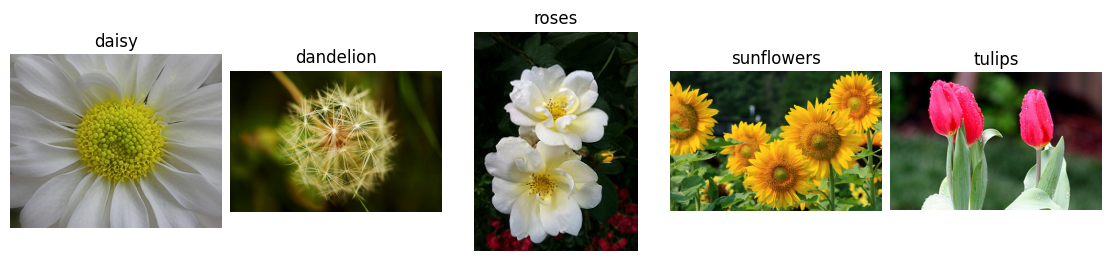

In [6]:
flower_archive = download(
    "flower_photos.tgz",
    "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz",
)
flower_root = CACHE / "flower_photos"
if not flower_root.exists():
    with TemporaryDirectory(dir=CACHE) as staging, tarfile.open(flower_archive) as archive:
        archive.extractall(staging, filter="data")
        (Path(staging) / flower_root.name).replace(flower_root)

image_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.PILToTensor(),
])
flowers = datasets.ImageFolder(flower_root, transform=image_transform)
flower_labels = np.asarray(flowers.targets)
display(pd.Series(np.bincount(flower_labels), index=flowers.classes,
                  name="Кількість зображень").to_frame())

examples = {
    "daisy": "100080576_f52e8ee070_n.jpg",
    "dandelion": "10043234166_e6dd915111_n.jpg",
    "roses": "10090824183_d02c613f10_m.jpg",
    "sunflowers": "1008566138_6927679c8a.jpg",
    "tulips": "100930342_92e8746431_n.jpg",
}
fig, axes = plt.subplots(1, len(examples), figsize=(11, 2.5), layout="constrained")
for ax, (label, filename) in zip(axes, examples.items()):
    ax.imshow(flowers.loader(flower_root / label / filename))
    ax.set_title(label)
    ax.axis("off")
plt.show()

### Поділ даних

Стратифіковано ділимо дані приблизно на 70% train, 15% validation і 15% test. Чверть train відбираємо з тієї самої навчальної частини, зберігаючи пропорції класів. Обидві моделі отримують однакові вибірки. Підготовлені тензори зберігаємо в пам’яті, щоб час навчання не включав повторне читання фотографій.

In [7]:
flower_train, flower_holdout = train_test_split(
    np.arange(len(flowers)), test_size=0.30, stratify=flower_labels, random_state=SEED,
)
flower_val, flower_test = train_test_split(
    flower_holdout, test_size=0.5, stratify=flower_labels[flower_holdout], random_state=SEED,
)
flower_small, _ = train_test_split(
    flower_train, train_size=0.25, stratify=flower_labels[flower_train], random_state=SEED,
)

images = torch.stack([image for image, _ in flowers]).float().div_(255)
images = transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225], inplace=True)(images)
flower_data = TensorDataset(images, torch.tensor(flower_labels, dtype=torch.long))
del images
image_val = loader(Subset(flower_data, flower_val), 64)
image_test = loader(Subset(flower_data, flower_test), 64)
print(f"Train 100% / train 25% / validation / test: "
      f"{len(flower_train)} / {len(flower_small)} / {len(flower_val)} / {len(flower_test)}")

Train 100% / train 25% / validation / test: 2569 / 642 / 550 / 551


### Власна CNN і донавчання MobileNetV3

**Згортка.** `Conv2d` переміщує навчуваний фільтр $3\times3$ по зображенню та обчислює зважену суму в кожній позиції. Ті самі ваги застосовуються в різних місцях, тож один фільтр може реагувати на край пелюстки в будь-якій частині кадру. `stride` задає крок фільтра, а `padding=1` додає нульове обрамлення на один піксель. Наступні шари поєднують прості контури й текстури в складніші ознаки.

**Зменшення карт ознак.** `BatchNorm2d` нормалізує активації за статистиками батча під час навчання, а під час оцінювання використовує накопичені статистики. `MaxPool2d(2)` бере максимум із кожної ділянки $2\times2$. Після трьох блоків маємо 64 карти $8\times8$. `AdaptiveAvgPool2d` зводить їх до $4\times4$, а `Flatten` формує вектор із 1024 значень. Dropout випадково зануляє частину ознак на train, після чого `Linear` повертає п’ять логітів.

**Перенесення навчання.** MobileNetV3 уже навчилася виділяти ознаки на ImageNet. Ранні блоки зберігаємо з їхніми вагами й статистиками BatchNorm через `requires_grad_(False)` і `frozen.eval()`. Останні три блоки донавчаємо з `lr=0.0003`, щоб поступово пристосувати ознаки до квітів. Новий класифікатор має п’ять виходів і навчається з `lr=0.001`.

In [8]:
def simple_cnn(classes):
    return nn.Sequential(
        nn.Conv2d(3, 16, 3, stride=2, padding=1), nn.BatchNorm2d(16), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(16, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),
        nn.AdaptiveAvgPool2d((4, 4)), nn.Flatten(), nn.Dropout(0.25),
        nn.Linear(64 * 4 * 4, classes),
    )


def flower_mobilenet(classes):
    model = mobilenet_v3_small(weights=MobileNet_V3_Small_Weights.IMAGENET1K_V1)
    frozen = model.features[:-3]
    frozen.requires_grad_(False)
    model.classifier = nn.Linear(model.classifier[0].in_features, classes)
    return model, frozen

### Експеримент із розміром train

Зовнішній цикл вибирає 25% або 100% train. Внутрішній цикл створює нову модель для кожного запуску й навчає її десять епох. Порівнюємо accuracy, macro F1, криві втрат і час до мінімуму validation loss.

Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 117MB/s]


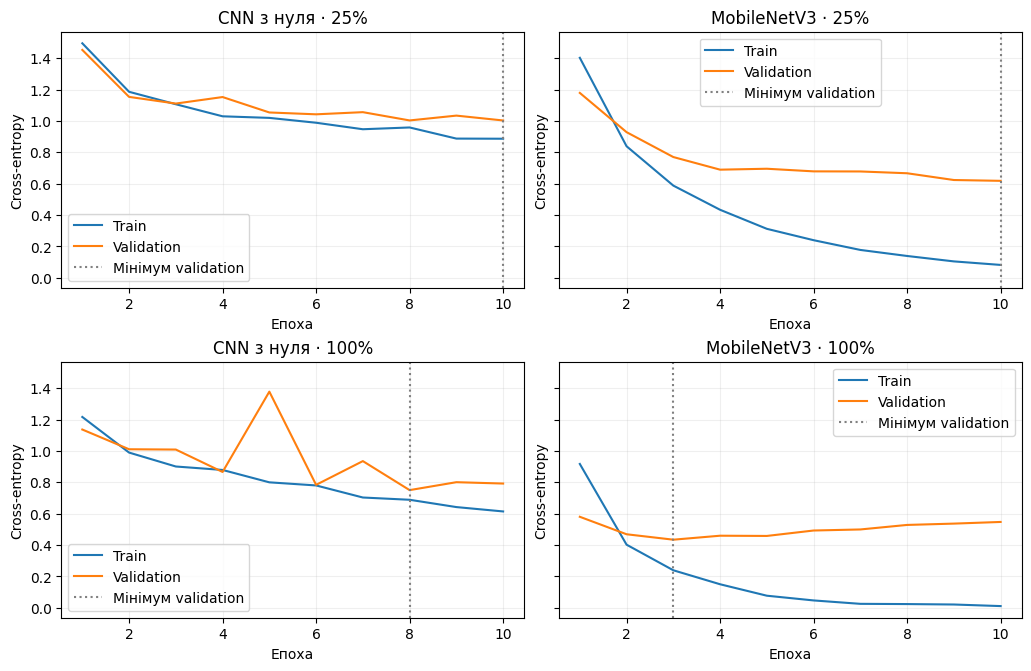

,Модель,Train,Accuracy,Macro F1,Val loss (1-ша),Найкраща епоха,Мін. val loss,Секунд до мін.,Секунд загалом
0,CNN з нуля,25%,0.6334,0.6243,1.4533,10,1.0032,38.8440,38.8440
1,MobileNetV3,25%,0.8040,0.7952,1.1790,10,0.6181,53.8216,53.8216
2,CNN з нуля,100%,0.7169,0.7105,1.1368,8,0.7503,96.0011,118.7564
3,MobileNetV3,100%,0.8711,0.8683,0.5801,3,0.4340,50.6295,170.7223


In [9]:
image_histories, image_results = {}, []
for name, indices in {"25%": flower_small, "100%": flower_train}.items():
    for architecture in ("CNN з нуля", "MobileNetV3"):
        image_train = loader(Subset(flower_data, indices), 64, shuffle=True)
        torch.manual_seed(SEED)
        if architecture == "CNN з нуля":
            model = simple_cnn(len(flowers.classes)).to(DEVICE)
            frozen = None
            optimizer = torch.optim.AdamW(model.parameters(), lr=0.001)
        else:
            model, frozen = flower_mobilenet(len(flowers.classes))
            model.to(DEVICE)
            optimizer = torch.optim.AdamW([
                {"params": model.features[-3:].parameters(), "lr": 0.0003},
                {"params": model.classifier.parameters(), "lr": 0.001},
            ])
        history = fit(model, image_train, image_val, optimizer, epochs=10,
                      loss_fn=cross_entropy, frozen=frozen)
        actual, predicted = predict(model, image_test)
        image_histories[f"{architecture} · {name}"] = history
        image_results.append({
            "Модель": architecture, "Train": name,
            "Accuracy": accuracy_score(actual, predicted),
            "Macro F1": f1_score(actual, predicted, average="macro"),
            **convergence(history),
        })

learning_curves(image_histories)
display(pd.DataFrame(image_results).round(4))

**Висновок.** На 642 зображеннях MobileNetV3 досягла 80,58% test accuracy, а власна CNN - 63,70%. З усіма 2 569 зображеннями точність зросла до 87,11% і 71,51% відповідно. На 25% train обидві моделі досягли мінімуму validation loss на останній, десятій епосі.

На 100% train MobileNetV3 досягла мінімуму validation loss за 3 епохи (17,8 с), власна CNN - за 8 (27,9 с). У збереженому запуску на CPU всі 10 епох тривали 58,5 с для MobileNetV3 і 34,8 с для власної CNN. Після третьої епохи train loss MobileNetV3 далі падав, а validation loss зростав. Це ознака перенавчання. У власної CNN крива validation loss коливалася й мала помітний стрибок на п’ятій епосі.

## 3. GRU для класифікації SMS

Використовуємо SMS Spam Collection із Lab 2. `ham` означає звичайне повідомлення, `spam` - спам. Повторюємо очищення Lab 2. `clean_text` декодує HTML, зводить текст до нижнього регістру, виділяє слова й прибирає стоп-слова. До поділу видаляємо порожні тексти, суперечливі мітки й дублікати. Зберігаємо той самий test, а validation виділяємо з навчальної частини.

[Набір даних UCI SMS Spam Collection](https://archive.ics.uci.edu/dataset/228/sms%2Bspam%2Bcollection)

In [10]:
sms_archive = download("sms_spam.zip",
    "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip")
with ZipFile(sms_archive) as archive:
    lines = archive.read("SMSSpamCollection").decode("utf-8-sig").splitlines()
sms = pd.DataFrame([line.split("\t", 1) for line in lines if line.strip()],
                   columns=["label", "text"])
stop_words = ENGLISH_STOP_WORDS | {"ll", "ve", "re"}


def clean_text(text):
    words = re.findall(r"[a-z]{2,}", html.unescape(text).lower())
    return " ".join(word for word in words if word not in stop_words)


sms["clean"] = sms["text"].map(clean_text)
sms = sms[sms["clean"] != ""]
consistent = sms.groupby("clean")["label"].transform("nunique") == 1
sms = sms[consistent].drop_duplicates("clean")
sms_labels = sms["label"].map({"ham": 0, "spam": 1}).to_numpy()
sms_tokens = sms["clean"].str.split().tolist()

sms_dev, sms_test = train_test_split(
    np.arange(len(sms)), test_size=0.2, stratify=sms_labels, random_state=SEED,
)
sms_train, sms_val = train_test_split(
    sms_dev, test_size=0.2, stratify=sms_labels[sms_dev], random_state=SEED,
)
print(f"Повідомлень: {len(sms)} | ham: {(sms_labels == 0).sum()} | spam: {(sms_labels == 1).sum()}")
print(f"Train / validation / test: {len(sms_train)} / {len(sms_val)} / {len(sms_test)}")

Повідомлень: 5015 | ham: 4441 | spam: 574
Train / validation / test: 3209 / 803 / 1003


### Словник і послідовності

Токенізація розбиває очищений текст на слова зі збереженням їхнього порядку. Словник, побудований за train, присвоює кожному слову цілий індекс. Індекс лише вказує, який рядок `Embedding` потрібно взяти. Невідомі слова отримують індекс 1 (`<unk>`). Truncation залишає перші 24 токени довгого повідомлення. Padding додає нулі (`<pad>`) справа до короткого. Так повідомлення можна об’єднати в тензор форми `[batch, 24]`.


In [11]:
counts = Counter(token for index in sms_train for token in sms_tokens[index])
vocab = {"<pad>": 0, "<unk>": 1}
vocab.update({token: index for index, (token, _) in enumerate(counts.most_common(), 2)})

MAX_LENGTH = 24
encoded_sms = torch.zeros((len(sms), MAX_LENGTH), dtype=torch.long)
for index, tokens in enumerate(sms_tokens):
    ids = [vocab.get(token, 1) for token in tokens[:MAX_LENGTH]]
    encoded_sms[index, :len(ids)] = torch.tensor(ids)

sms_data = TensorDataset(encoded_sms, torch.tensor(sms_labels, dtype=torch.long))
print(f"Словник: {len(vocab)} | Обрізано train-повідомлень: "
      f"{sum(len(sms_tokens[i]) > MAX_LENGTH for i in sms_train)}")

Словник: 5761 | Обрізано train-повідомлень: 28


### Embedding, GRU і GloVe

**Embedding.** `nn.Embedding` зберігає таблицю з одним 50-вимірним вектором на токен. Заміна індексів рядками цієї таблиці дає тензор `[batch, 24, 50]`. Під час навчання градієнти оновлюють вектори, які вплинули на прогноз. `padding_idx=0` фіксує нульовий вектор для доповнення.

**GRU.** На кроці $t$ мережа отримує вектор поточного слова та прихований стан попереднього кроку $h_{t-1}$. Вентиль скидання визначає, скільки попереднього стану врахувати під час побудови нового кандидата. Вентиль оновлення визначає, як змішати цей кандидат зі старим станом. Так GRU накопичує контекст повідомлення. `nn.GRU` повертає 48-вимірний стан для кожного кроку. `last` показує позицію останнього справжнього токена. Беремо саме цей стан, оскільки наступні кроки з padding теж можуть змінити стан рекурентного шару.

**GloVe.** Готові вектори навчені за статистикою спільної появи слів у великому корпусі. Слова зі схожими контекстами часто мають близькі вектори. В одному запуску всі вектори слів починаються з випадкових значень, а в другому збіги зі словником GloVe отримують готові вектори. Для слів без збігу зберігаємо випадкові значення. Обидва набори векторів донавчаються разом із GRU.


In [12]:
EMBED_DIM = 50
glove_file = download(
    "glove-wiki-gigaword-50.gz",
    "https://github.com/RaRe-Technologies/gensim-data/releases/download/"
    "glove-wiki-gigaword-50/glove-wiki-gigaword-50.gz",
)
glove_vectors = {}
with gzip.open(glove_file, "rt", encoding="utf-8") as vectors:
    next(vectors)  # Заголовок word2vec: кількість слів і розмірність.
    for line in vectors:
        word, values = line.split(" ", 1)
        if word in vocab:
            glove_vectors[vocab[word]] = torch.tensor(np.fromstring(values, sep=" ",
                                                                     dtype=np.float32))

print(f"Покриття словника GloVe: {len(glove_vectors)}/{len(vocab) - 2} "
      f"({len(glove_vectors) / (len(vocab) - 2):.1%})")


class SMSClassifier(nn.Module):
    def __init__(self, vocab_size):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, EMBED_DIM, padding_idx=0)
        with torch.no_grad():
            self.embedding.weight.normal_(std=0.4)
            self.embedding.weight[0].zero_()
        self.gru = nn.GRU(EMBED_DIM, 48, batch_first=True)
        self.classifier = nn.Sequential(nn.Dropout(0.2), nn.Linear(48, 2))

    def forward(self, tokens):
        states, _ = self.gru(self.embedding(tokens))
        last = (tokens != 0).sum(dim=1) - 1
        rows = torch.arange(len(tokens), device=tokens.device)
        return self.classifier(states[rows, last])

Покриття словника GloVe: 4804/5759 (83.4%)


### Навчання і перевірка на спамі

Два запуски мають однакові початкові ваги GRU та класифікатора. Більша вага класу `spam` у loss враховує його меншу частоту. Precision для спаму - частка справжнього спаму серед позначених моделлю повідомлень. Recall - частка знайденого спаму серед усіх спам-повідомлень. F1 поєднує обидві метрики як їхнє гармонійне середнє.

Зважена перехресна ентропія оцінює ймовірності класів. F1 оцінює кінцеві мітки після вибору найбільшого логіта. Тому мінімум validation loss і максимум F1 можуть припадати на різні моделі.

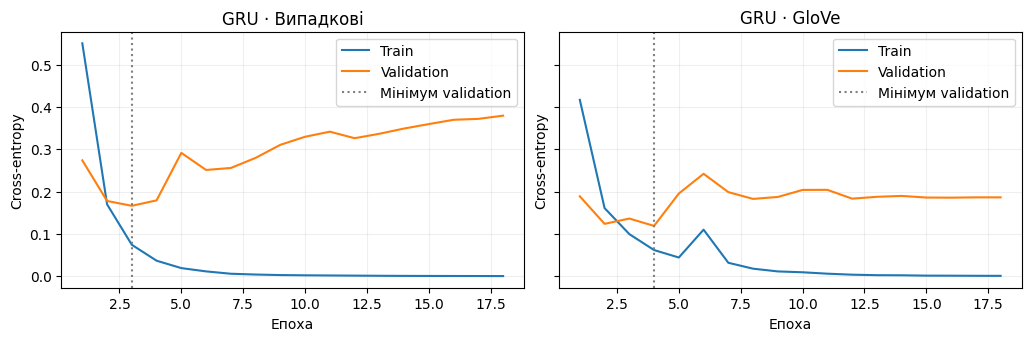

,Модель,Accuracy,Macro F1,Spam precision,Spam recall,Spam F1,Val loss (1-ша),Найкраща епоха,Мін. val loss,Секунд до мін.,Секунд загалом
0,GRU · Випадкові,0.9531,0.8915,0.7576,0.8696,0.8097,0.2738,3,0.1665,2.9629,17.1233
1,GRU · GloVe,0.9143,0.8286,0.5810,0.9043,0.7075,0.1889,4,0.1190,4.0450,18.1471


In [13]:
class_weights = len(sms_train) / (2 * np.bincount(sms_labels[sms_train]))
sms_loss = nn.CrossEntropyLoss(
    weight=torch.tensor(class_weights, dtype=torch.float32, device=DEVICE),
    reduction="none",
)
text_val = loader(Subset(sms_data, sms_val), 64)
text_test = loader(Subset(sms_data, sms_test), 64)
text_histories, text_results = {}, []
for name, use_glove in (("GRU · Випадкові", False), ("GRU · GloVe", True)):
    torch.manual_seed(SEED)
    model = SMSClassifier(len(vocab))
    if use_glove:
        with torch.no_grad():
            indices = list(glove_vectors)
            model.embedding.weight[indices] = torch.stack(list(glove_vectors.values()))
    model.to(DEVICE)
    text_train = loader(Subset(sms_data, sms_train), 64, shuffle=True)
    history = fit(model, text_train, text_val, torch.optim.AdamW(model.parameters(), lr=0.002),
                  epochs=18, loss_fn=sms_loss)
    target, predicted = predict(model, text_test)
    precision, recall, f1, _ = precision_recall_fscore_support(
        target, predicted, average="binary", zero_division=0,
    )
    text_histories[name] = history
    text_results.append({
        "Модель": name,
        "Accuracy": accuracy_score(target, predicted),
        "Macro F1": f1_score(target, predicted, average="macro"),
        "Spam precision": precision, "Spam recall": recall,
        "Spam F1": f1, **convergence(history),
    })

learning_curves(text_histories)
display(pd.DataFrame(text_results).round(4))

**Висновок.** GloVe дала нижчий validation loss після першої епохи (0,189 проти 0,274). Її мінімум припав на четверту епоху, а мінімум моделі з випадковими векторами - на третю. У збереженому запуску на CPU навчання тривало 9,8 с із GloVe і 9,3 с із випадковими векторами. Після мінімуму в обох моделях train loss наближався до нуля, а validation loss зростав, особливо в моделі з випадковими векторами.

На тесті GRU з GloVe знайшла 104 зі 115 спам-повідомлень проти 100 у моделі з випадковими векторами. Кількість звичайних повідомлень, помилково позначених як спам, зросла з 32 до 75. Тому F1 для спаму знизився з 0,810 до 0,708, а accuracy - з 95,31% до 91,43%.